In [3]:
import numpy as np
import pandas as pd

In [4]:
df = pd.read_csv("placement.csv")

In [5]:
df

,Unnamed: 0,cgpa,iq,placement
0,0,6.7,121.0,0
1,1,9.3,128.0,1
2,2,8.3,138.0,1
3,3,7.7,141.0,1
4,4,5.7,150.0,0
...,...,...,...,...
95,95,7.2,142.0,1
96,96,7.4,133.0,1
97,97,6.9,115.0,0
98,98,5.1,121.0,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [7]:
df = df.iloc[:,1:]

In [8]:
df.head()

,cgpa,iq,placement
0,6.7,121.0,0
1,9.3,128.0,1
2,8.3,138.0,1
3,7.7,141.0,1
4,5.7,150.0,0


In [9]:
import matplotlib.pyplot as plt

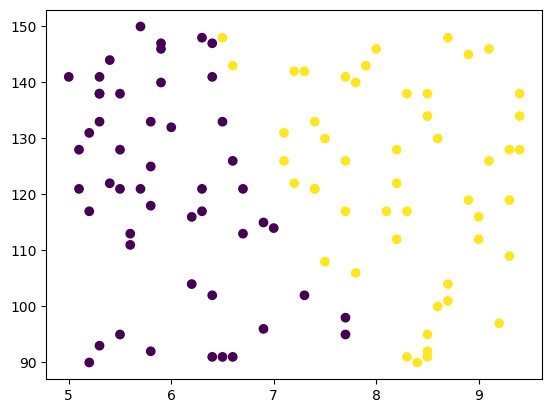

In [10]:
plt.scatter(df['cgpa'],df['iq'], c=df['placement'])

In [11]:
X = df.iloc[:,0:2]
Y = df.iloc[:,-1]

In [12]:
X

,cgpa,iq
0,6.7,121.0
1,9.3,128.0
2,8.3,138.0
3,7.7,141.0
4,5.7,150.0
...,...,...
95,7.2,142.0
96,7.4,133.0
97,6.9,115.0
98,5.1,121.0


In [13]:
Y

,placement
0,0
1,1
2,1
3,1
4,0
...,...
95,1
96,1
97,0
98,0


In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size = 0.1)

In [18]:
X_test

,cgpa,iq
41,7.2,122.0
37,5.4,144.0
24,7.1,131.0
26,5.9,146.0
45,8.0,146.0
80,8.9,145.0
12,8.7,104.0
40,5.5,128.0
17,7.4,121.0
38,8.1,117.0


In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
scalar = StandardScaler()

In [21]:
X_train = scalar.fit_transform(X_train)

In [22]:
X_train

array([[-0.59629175,  1.53514559],
       [ 0.88825203, -1.68715265],
       [ 1.18516079,  1.53514559],
       [-0.9674277 , -1.6306211 ],
       [ 0.88825203, -0.2173324 ],
       [-0.299383  , -0.44345859],
       [ 0.51711608,  1.08289321],
       [-1.56124521,  1.13942476],
       [ 1.70475111,  0.74370392],
       [-0.52206456, -1.06530562],
       [ 1.70475111,  0.40451463],
       [-1.41279083, -1.74368419],
       [ 0.81402484, -0.49999014],
       [ 0.29443452,  0.51757773],
       [ 0.44288889,  1.13942476],
       [-0.15092862, -1.40449491],
       [ 0.44288889,  0.29145154],
       [ 0.44288889, -0.2173324 ],
       [ 1.03670641, -1.6306211 ],
       [-1.41279083,  0.57410928],
       [ 1.70475111,  0.96983011],
       [ 0.44288889, -1.46102645],
       [ 1.48206954,  1.4220825 ],
       [-1.19010927,  0.96983011],
       [-0.44783737,  0.68717237],
       [-0.15092862, -0.33039549],
       [-1.19010927, -1.46102645],
       [ 0.07175295,  1.19595631],
       [ 1.63052392,

In [27]:
from sklearn.linear_model import LogisticRegression

In [28]:
clf = LogisticRegression()

In [31]:
clf.fit(X_train,Y_train)

LogisticRegression()

In [48]:
Y_pred = clf.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [50]:
Y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [51]:
Y_test

,placement
41,1
37,0
24,1
26,0
45,1
80,1
12,1
40,0
17,1
38,1


In [52]:
from sklearn.metrics import accuracy_score


In [53]:
accuracy_score(Y_test,Y_pred)

0.7

In [54]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

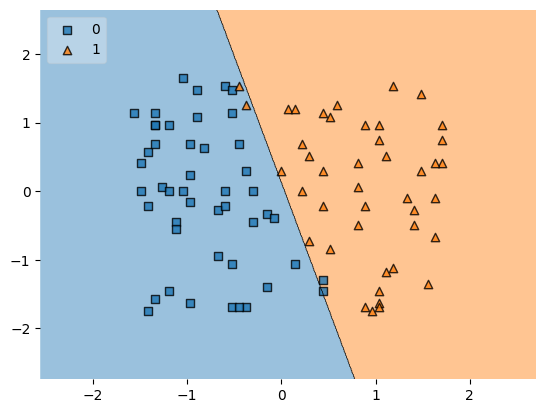

In [58]:
plot_decision_regions(X_train, Y_train.values, clf=clf, legend=2)

In [59]:
import pickle

In [61]:
pickle.dump(clf,open('model.pkl','wb'))